Models and optimal parameters loaded successfully!
=== [Feature A] Generating Process Window & Forbidden Zone Map ===
=== [Feature B] Running Chamber Aging & Drift Simulation ===
=== [Feature C] Running Multi-Target Inverse Design ===


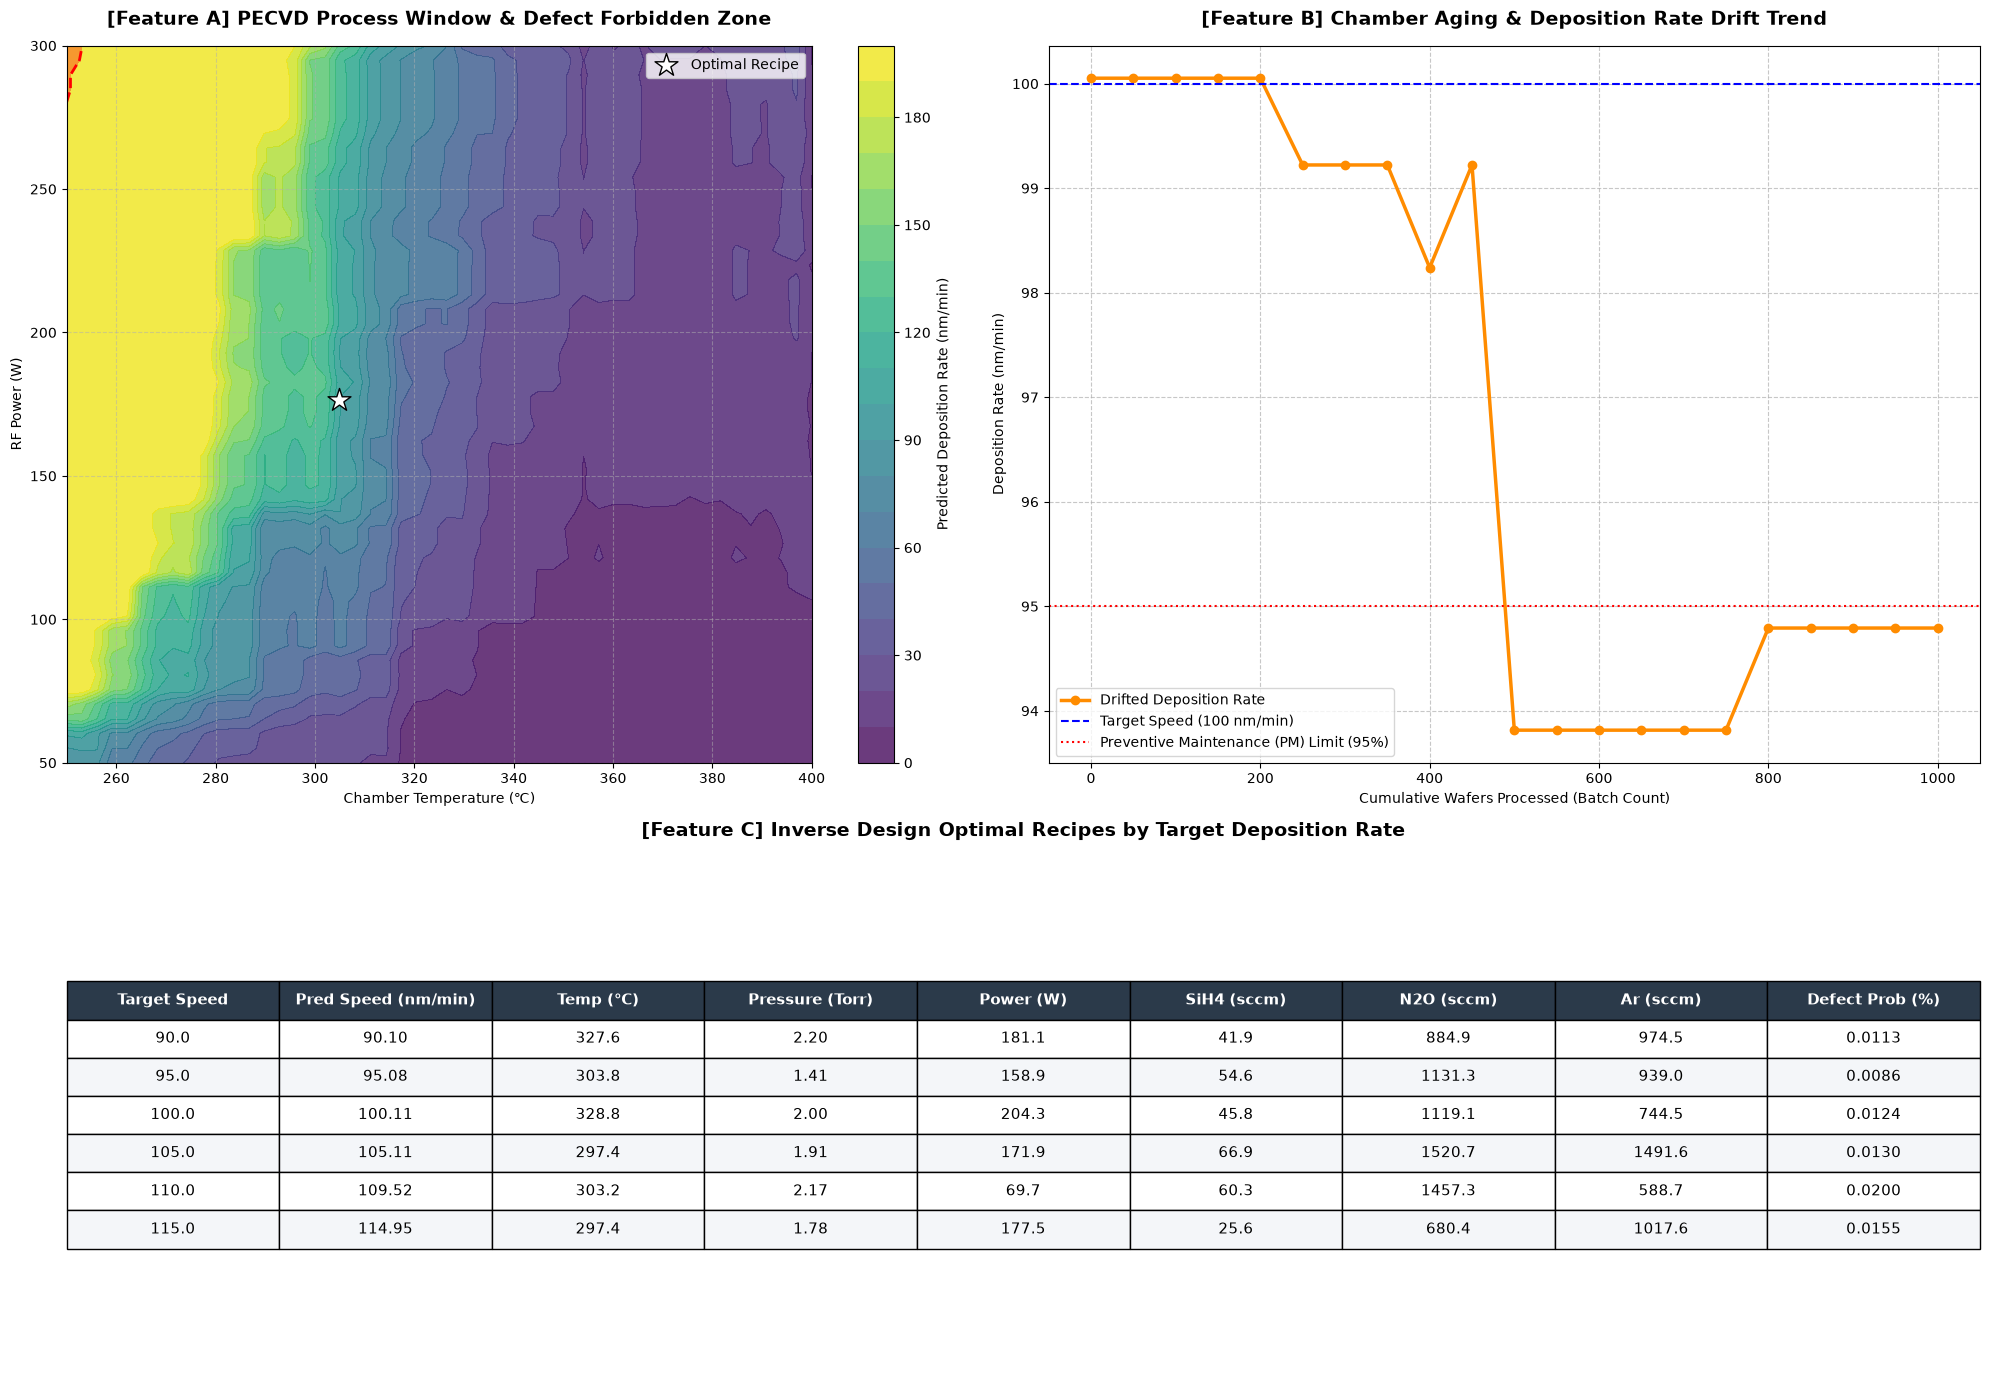

In [22]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import seaborn as sns
from scipy.optimize import minimize
from scipy.optimize import differential_evolution
from sklearn.model_selection import RandomizedSearchCV
from matplotlib.gridspec import GridSpec
import warnings

# i.   Suppress non-critical runtime/convergence warnings for cleaner notebook output
warnings.filterwarnings('ignore')

# ii.  Load Saved Optimal Recipe Parameters Directly in a New Notebook or Script
# [1] Restores the dictionary of optimized controllable process setpoints exported from the previous stage
opt_params = joblib.load('optimal_recipe_params.pkl')

# [2] Unpack Dictionary Keys into Current Session Globals
globals().update(opt_params)

# [3] Compute Derived Process & Kinetic Baseline Variables at the Optimal Recipe
opt_total_flow = opt_sih4 + opt_n2o + opt_ar
opt_inverse_temp = 1 / (opt_temp + 273.15)
opt_residence_time = opt_press / opt_total_flow

# [4] Load Pre-Trained XGBoost Surrogate Models
# a. Deposition rate regression surrogate (predicts log1p-transformed growth rate)
best_xgb_speed = joblib.load('xgb_speed_model.pkl')
# b. Binary defect classification surrogate (predicts probability of exceeding non-uniformity/defect limit)
xgb_defect = joblib.load('xgb_defect_model.pkl')
print("Models and optimal parameters loaded successfully!")

# iii. Process Window Contour & Forbidden Zone Map
print("=== [Feature A] Generating Process Window & Forbidden Zone Map ===")

# [1] Partition chamber temperature and RF power operating ranges into a fine 2D evaluation grid
temp_grid = np.linspace(250, 400, 50)
power_grid = np.linspace(50, 300, 50)
T_mesh, P_mesh = np.meshgrid(temp_grid, power_grid)

# [2] Hold remaining controllable recipe parameters at the optimal recipe setpoints
fixed_press = opt_press 
fixed_sih4 = opt_sih4 
fixed_n2o = opt_n2o 
fixed_ar = opt_ar 
fixed_total_flow = fixed_sih4 + fixed_n2o + fixed_ar

# [3] Pre-allocate 2D arrays for predicted deposition rate (nm/min) and defect probability
speed_mesh = np.zeros_like(T_mesh)
defect_mesh = np.zeros_like(T_mesh)

# [4] Evaluate both trained XGBoost surrogates across every (temperature, power) grid coordinate
for i in range(T_mesh.shape[0]):
    for j in range(T_mesh.shape[1]):
        t = T_mesh[i, j]
        p = P_mesh[i, j]

        # a. Recompute physics-informed features dynamically for each grid operating point
        curr_density = p * fixed_press
        curr_residence = fixed_press / fixed_total_flow
        curr_energy = p / fixed_total_flow
        curr_inv_temp = 1 / (t + 273.15)

        # b. Build single-observation feature array matching the surrogate training schema
        inp = np.array([[curr_density, curr_residence, curr_energy, 
                         curr_inv_temp, fixed_sih4, fixed_n2o, fixed_ar]])
        
        # c. Invert log1p deposition rate prediction back to nm/min and clip to [0, 200] for plotting
        pred_log = best_xgb_speed.predict(inp)[0]
        speed_mesh[i, j] = np.clip(np.expm1(pred_log), 0, 200)

        # d. Extract predicted probability of class 1 (defect) from the classification surrogate
        defect_mesh[i, j] = xgb_defect.predict_proba(inp)[0][1] 

# iv.  Chamber Aging & Deposition Rate Drift Simulation
print("=== [Feature B] Running Chamber Aging & Drift Simulation ===")

# [1] Cumulative wafer count from 0 to 1,000 wafers in 50-wafer intervals
wafers_processed = np.arange(0, 1001, 50)
drift_speeds = []

# [2] Baseline feature vector evaluated at the optimal recipe setpoints
base_inp = np.array([[opt_power * opt_press, 
                      opt_residence_time, 
                      opt_power / opt_total_flow, 
                      opt_inverse_temp, 
                      opt_sih4, opt_n2o, opt_ar]])

# [4] Model progressive chamber wall fouling/byproduct accumulation with cumulative wafer throughput
for w in wafers_processed:
    # a. Including small Gaussian run-to-run fluctuation around the aging trend
    aging_factor = 1.0 - (w * 0.00015) + np.random.normal(0, 0.005)
    
    # b. Perturb effective plasma density proxy to reflect chamber wall condition drift
    aged_inp = base_inp.copy()
    aged_inp[0, 0] *= aging_factor 

    # c. Predict drifted deposition rate (nm/min) from log1p surrogate output
    pred_log = best_xgb_speed.predict(aged_inp)[0]
    drift_speeds.append(np.expm1(pred_log))

# v.   Inverse Design - Multi-Target Recipe Solver
print("=== [Feature C] Running Multi-Target Inverse Design ===")

# [1] Explicit search bounds for the 6 controllable PECVD hardware/recipe parameters
real_bounds = [
    (250, 400),     # Chamber temperature (°C)
    (1.0, 5.0),     # Chamber pressure (Torr)
    (50,  300),     # RF plasma power (W)
    (10.0, 100.0),  # SiH4 precursor flow rate (sccm)
    (200, 2000.0),  # N2O oxidant flow rate (sccm)
    (200, 2000.0)   # Ar diluent/plasma gas flow rate (sccm)
]

# [2] Solve Optimal Recipe for Multiple Targets
def inverse_design_recommendation(target_speeds=[90.0, 95.0, 100.0, 105.0, 110.0, 115.0]):
    recommendations = []
    
    for target in target_speeds:
        # a-1. Per-target objective balancing deposition rate accuracy against defect risk & stoichiometry
        def local_objective(x):
            t_c, press, pow_w, sih4, n2o, ar = x
            # a-2. Enforce RF power safety cap (<= 250 W) and minimum N2O/SiH4 ratio (>= 20)
            if pow_w > 250 or (n2o / sih4 < 20): return 1e6

            # a-3. Recompute physics-derived features consistently for candidate operating point
            tot_f = sih4 + n2o + ar
            dens = pow_w * press
            resi = press / tot_f
            eng = pow_w / tot_f
            inv_t = 1 / (t_c + 273.15)
            
            inp = np.array([[dens, resi, eng, inv_t, sih4, n2o, ar]])
            p_speed = np.expm1(best_xgb_speed.predict(inp)[0])
            d_prob = xgb_defect.predict_proba(inp)[0][1]

            # a-4. Minimize target growth rate error while heavily penalizing predicted defect probability
            return abs(p_speed - target) + (d_prob * 10000)

        # b. Optimize candidate controllable recipe via Differential Evolution global search    
        res = differential_evolution(local_objective, real_bounds, seed=int(target), maxiter=100)
        t, pr, pw, s, n, a = res.x
        
        # c. Re-evaluate surrogate predictions at the converged optimal recipe point for reporting
        tot_f = s + n + a
        final_inp = np.array([[pw*pr, pr/tot_f, pw/tot_f, 1/(t+273.15), s, n, a]])
        predicted_rate = np.expm1(best_xgb_speed.predict(final_inp)[0])
        defect_p = xgb_defect.predict_proba(final_inp)[0][1] * 100
        
        recommendations.append({
            'Target Speed': f'{target:.1f}',
            'Pred Speed (nm/min)': f'{predicted_rate:.2f}',
            'Temp (℃)': f'{t:.1f}',
            'Pressure (Torr)': f'{pr:.2f}',
            'Power (W)': f'{pw:.1f}',
            'SiH4 (sccm)': f'{s:.1f}',
            'N2O (sccm)': f'{n:.1f}',
            'Ar (sccm)': f'{a:.1f}',
            'Defect Prob (%)': f'{defect_p:.4f}',
        })
        
    return pd.DataFrame(recommendations)

# [3] Execute inverse design across target deposition rates and build summary table DataFrame
inverse_recipe_df = inverse_design_recommendation()

# vi. Printing Results 
fig = plt.figure(figsize=(20, 14))
gs = GridSpec(2, 2, height_ratios=[1.15, 0.85], figure=fig)

# [1] PECVD Process Window & Defect Forbidden Zone
# a. Filled contour plot of predicted deposition rate (nm/min) across temperature and RF power
ax_a =fig.add_subplot(gs[0,0])
cs = plt.contourf(T_mesh, P_mesh, speed_mesh, levels=20, cmap='viridis', alpha=0.8, vmin=0, vmax=200)
cbar = plt.colorbar(cs, ax=ax_a)
cbar.set_label('Predicted Deposition Rate (nm/min)')

# b. Overlay semi-transparent red shading and dashed boundary around elevated defect probability regions
ax_a.contourf(T_mesh, P_mesh, defect_mesh, levels=[0.01, 1.0], colors=['red'], alpha=0.35)
ax_a.contour(T_mesh, P_mesh, defect_mesh, levels=[0.01], colors='red', linewidths=2, linestyles='--')

# c. Mark the inverse-optimized recipe operating point on the process window map
ax_a.scatter([opt_temp], [opt_power], color='white', marker='*', s=300, edgecolor='black', label='Optimal Recipe')
ax_a.set_title('[Feature A] PECVD Process Window & Defect Forbidden Zone', fontsize=14, fontweight='bold', pad=15)
ax_a.set_xlabel('Chamber Temperature (℃)')
ax_a.set_ylabel('RF Power (W)')
ax_a.grid(True, linestyle='--', alpha=0.5)
ax_a.legend(loc='upper right')

# [2] Chamber Aging & Deposition Rate Drift Trend
ax_b = fig.add_subplot(gs[0, 1])
ax_b.plot(wafers_processed, drift_speeds, marker='o', color='darkorange', linewidth=2.5, label='Drifted Deposition Rate')
ax_b.axhline(y=100.0, color='blue', linestyle='--', label='Target Speed (100 nm/min)')
ax_b.axhline(y=95.0, color='red', linestyle=':', label='Preventive Maintenance (PM) Limit (95%)')
ax_b.set_title('[Feature B] Chamber Aging & Deposition Rate Drift Trend', fontsize=14, fontweight='bold', pad=15)
ax_b.set_xlabel('Cumulative Wafers Processed (Batch Count)')
ax_b.set_ylabel('Deposition Rate (nm/min)')
ax_b.grid(True, linestyle='--', alpha=0.7)
ax_b.legend(loc='lower left')

# [3] Inverse Design Optimal Recipes by Target Deposition Rate
ax_c = fig.add_subplot(gs[1, :])
ax_c.axis('off')
ax_c.set_title(
    '[Feature C] Inverse Design Optimal Recipes by Target Deposition Rate',
    fontsize=14,fontweight='bold',pad=10,)

# a. Render DataFrame as a clean Matplotlib table inside the bottom panel
table = ax_c.table(cellText=inverse_recipe_df.values,colLabels=inverse_recipe_df.columns,loc='center',cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.0, 1.8)

# b. Style header row distinctly for readability
for (row, col), cell in table.get_celld().items():
    if row == 0:
        cell.set_text_props(weight='bold', color='white')
        cell.set_facecolor('#2b3a4a')
    elif row % 2 == 0:
        cell.set_facecolor('#f4f6f9')

# [4] Output
plt.tight_layout()
plt.show()

